# ML Kernel Roofline Analysis

Choose one or more kernels in the setting cell, then run the remaining cells to filter the measurements and create plots. Current benchmark options are GEMM, elementwise add, elementwise multiply, and fused multiply-add. Future candidates include convolution, softmax, and LayerNorm.

In [1]:
# Select one or more operation IDs. Use ["all"] to plot every operation in the CSV.
KERNEL_OPTIONS = {
    'matmul': 'Matrix multiplication (GEMM)',
    'add': 'Elementwise addition',
    'multiply': 'Elementwise multiplication',
    'fused_mul_add': 'Fused elementwise multiply-add',
}
SELECTED_KERNELS = ['matmul']

unknown = set(SELECTED_KERNELS) - {'all'} - set(KERNEL_OPTIONS)
if unknown:
    raise ValueError(f'Unknown kernel IDs: {sorted(unknown)}')
print('Available kernels:')
for kernel_id, description in KERNEL_OPTIONS.items():
    selected = ' (selected)' if 'all' in SELECTED_KERNELS or kernel_id in SELECTED_KERNELS else ''
    print(f'  {kernel_id}: {description}{selected}')


Available kernels:
  matmul: Matrix multiplication (GEMM) (selected)
  add: Elementwise addition
  multiply: Elementwise multiplication
  fused_mul_add: Fused elementwise multiply-add


In [2]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('../results/optimization_comparison.csv')
all_df = pd.read_csv(csv_path)
if 'all' in SELECTED_KERNELS:
    selected = set(all_df['operation'].unique())
else:
    selected = set(SELECTED_KERNELS)
missing = selected - set(all_df['operation'].unique())
if missing:
    print(f'No measurements loaded for: {sorted(missing)}. Re-run run_benchmarks.py with those operation IDs and output to results/optimization_comparison.csv.')
df = all_df[all_df['operation'].isin(selected)].copy()
if df.empty:
    raise ValueError('None of the selected kernels have measurements in the loaded CSV.')
display_df = df.copy()
display_df['device'] = display_df['device'].replace({'mps': 'GPU'})
display_df.head()

,operation,size,device,precision,variant,median_ms,operations,gflops,modeled_bytes,estimated_gb_per_s,arithmetic_intensity,max_abs_error,worker_threads
9,matmul,128,cpu,fp32,naive,0.416854,4194304,10.061800,16842752,40.404400,0.249027,0.0,4
10,matmul,128,cpu,fp32,tiled,0.136813,4194304,30.657300,589824,4.311190,7.111110,0.0,4
11,matmul,128,cpu,fp32,torch,0.006021,4194304,696.612471,196608,32.653710,21.333333,0.0,6
12,matmul,128,GPU,fp32,naive,0.541729,4194304,7.742439,16842752,31.090734,0.249027,0.0,0
13,matmul,128,GPU,fp32,tiled,0.499812,4194304,8.391755,1114112,2.229060,3.764706,0.0,0


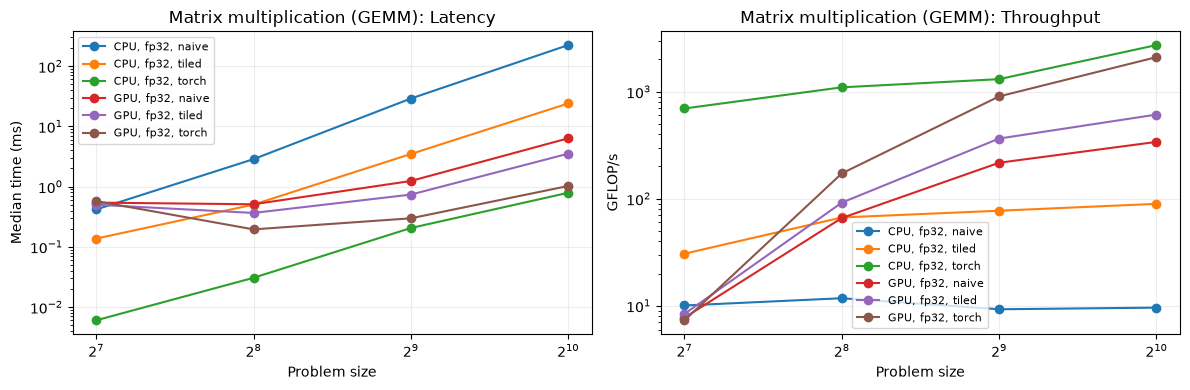

In [3]:
# Latency and throughput versus problem size. Matmul size is N for NxN @ NxN;
# elementwise size is the number of elements.
kernel_names = {key: value for key, value in KERNEL_OPTIONS.items()}
for operation, group in df.groupby('operation'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for (device, precision, variant), series in group.groupby(['device', 'precision', 'variant']):
        series = series.sort_values('size')
        device_name = 'GPU' if device == 'mps' else device.upper()
        label = f'{device_name}, {precision}, {variant}'
        axes[0].plot(series['size'], series['median_ms'], marker='o', label=label)
        axes[1].plot(series['size'], series['gflops'], marker='o', label=label)
    for ax, ylabel, title in [(axes[0], 'Median time (ms)', 'Latency'),
                              (axes[1], 'GFLOP/s', 'Throughput')]:
        ax.set_xscale('log', base=2)
        ax.set_yscale('log')
        ax.set_xlabel('Problem size')
        ax.set_ylabel(ylabel)
        ax.set_title(f'{kernel_names.get(operation, operation)}: {title}')
        ax.grid(True, which='major', alpha=.22)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

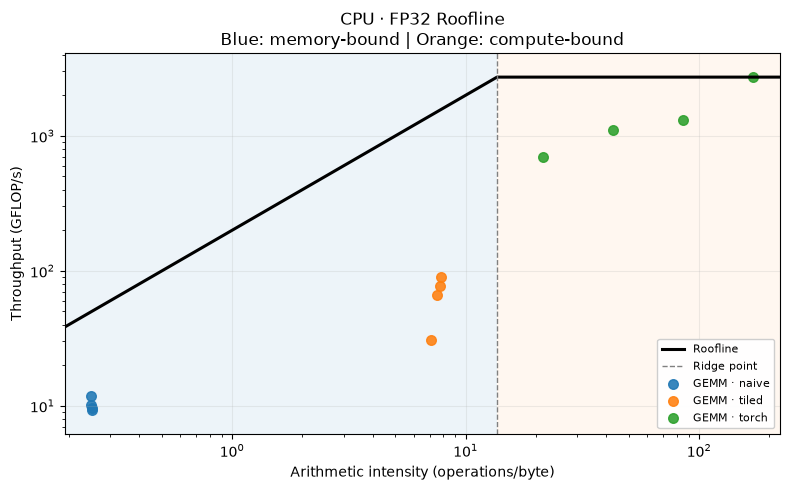

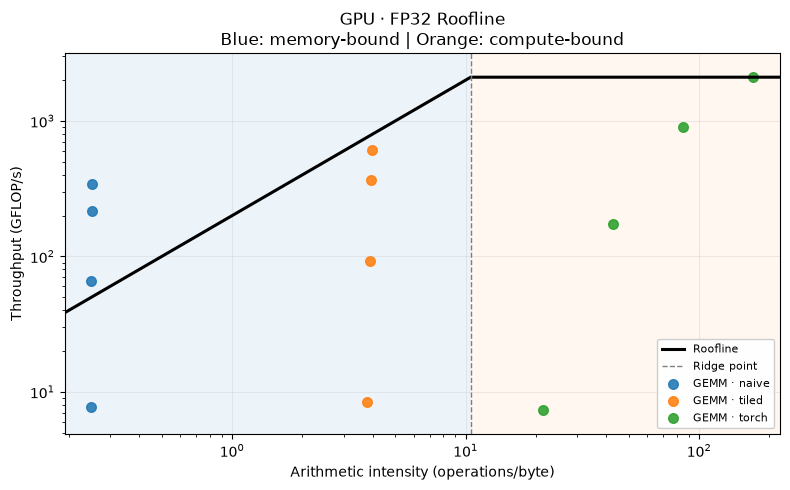

In [4]:
# Plot each device and precision separately. The custom comparisons share the
# GPU with PyTorch, so each variant appears on the same axes.
MEMORY_BANDWIDTH_GB_S = 200.0
COMPUTE_PEAK_OVERRIDE_GFLOPS = {
    # Optional sourced overrides, e.g. ('GPU', 'fp32'): 10000.0
}

for (device, precision), group in df.groupby(['device', 'precision']):
    reference_gemm = all_df[(all_df['device'] == device) &
                            (all_df['precision'] == precision) &
                            (all_df['operation'] == 'matmul')]
    device_name = 'GPU' if device == 'mps' else device.upper()
    measured_gemm_roof = (reference_gemm['gflops'].max() if not reference_gemm.empty
                          else group['gflops'].max())
    compute_roof = COMPUTE_PEAK_OVERRIDE_GFLOPS.get(
        (device_name, precision), measured_gemm_roof)
    knee = compute_roof / MEMORY_BANDWIDTH_GB_S
    data_min = group['arithmetic_intensity'].min()
    data_max = group['arithmetic_intensity'].max()
    x_min = min(data_min / 1.3, knee / 1.5)
    x_max = data_max * 1.3
    xs = pd.Series(sorted({x_min, knee, x_max}))
    roof = (MEMORY_BANDWIDTH_GB_S * xs).clip(upper=compute_roof)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(max(group['gflops'].min() / 1.5, 1e-3), compute_roof * 1.5)
    ax.axvspan(x_min, knee, color='tab:blue', alpha=.08, linewidth=0)
    ax.axvspan(knee, x_max, color='tab:orange', alpha=.06, linewidth=0)
    ax.plot(xs, roof, color='black', linewidth=2.2, label='Roofline')
    ax.axvline(knee, color='gray', linestyle='--', linewidth=1, label='Ridge point')

    markers = {'matmul': 'o', 'fused_mul_add': 's', 'add': '^', 'multiply': 'D'}
    names = {'matmul': 'GEMM', 'fused_mul_add': 'Fused mul-add',
             'add': 'Add', 'multiply': 'Multiply'}
    for (operation, variant), points in group.groupby(['operation', 'variant']):
        ax.scatter(points['arithmetic_intensity'], points['gflops'],
                   marker=markers[operation], s=48,
                   label=f'{names[operation]} · {variant}', alpha=.88)

    ax.set_title(f'{device_name} · {precision.upper()} Roofline\nBlue: memory-bound | Orange: compute-bound')
    ax.set_xlabel('Arithmetic intensity (operations/byte)')
    ax.set_ylabel('Throughput (GFLOP/s)')
    ax.grid(True, which='major', alpha=.22)
    ax.legend(loc='lower right', fontsize=8, framealpha=.95)
    plt.tight_layout()
    plt.show()

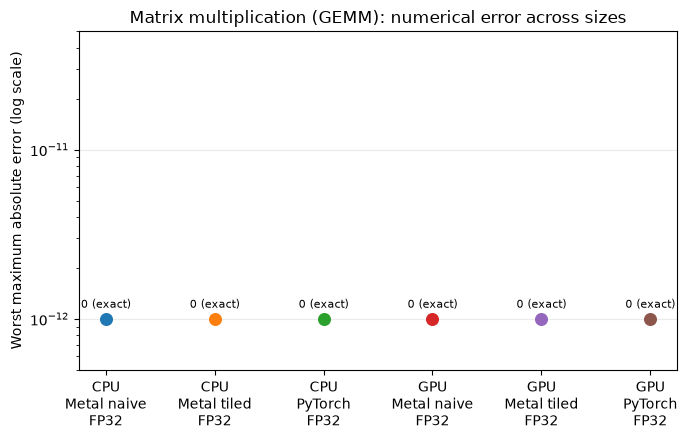

In [5]:
# Plot the worst absolute error for each implementation across tested sizes.
# Exact zeros are placed at a small positive floor so the log axis stays valid.
error_floor = 1e-12
variant_names = {
    'torch': 'PyTorch',
    'torch_eager': 'PyTorch eager',
    'naive': 'Metal naive',
    'tiled': 'Metal tiled',
    'metal_fused': 'Metal fused',
}
for operation, group in df.groupby('operation'):
    summary = (group.groupby(['device', 'precision', 'variant'], as_index=False)
               ['max_abs_error'].max())
    summary['plot_error'] = summary['max_abs_error'].clip(lower=error_floor)
    labels = [f"{'GPU' if r.device == 'mps' else r.device.upper()}\n{variant_names.get(r.variant, r.variant)}\n{r.precision.upper()}"
              for r in summary.itertuples()]
    x = range(len(summary))
    colors = [plt.get_cmap('tab10')(i % 10) for i in x]

    fig, ax = plt.subplots(figsize=(max(7, len(summary) * 1.15), 4.5))
    for i, row in summary.iterrows():
        ax.scatter(i, row['plot_error'], color=colors[i], s=70, zorder=3)
        text = '0 (exact)' if row['max_abs_error'] == 0 else f"{row['max_abs_error']:.1e}"
        ax.annotate(text, (i, row['plot_error']), xytext=(0, 8),
                    textcoords='offset points', ha='center', fontsize=8)

    max_value = max(summary['plot_error'].max(), error_floor * 10)
    ax.set_yscale('log')
    ax.set_ylim(error_floor / 2, max_value * 5)
    ax.set_xticks(list(x), labels)
    ax.set_ylabel('Worst maximum absolute error (log scale)')
    ax.set_title(f"{KERNEL_OPTIONS.get(operation, operation)}: numerical error across sizes")
    ax.grid(True, axis='y', which='major', alpha=.25)
    plt.tight_layout()
    plt.show()